<a href="https://colab.research.google.com/github/sanketmoralwar-datascience/Learning-Python/blob/main/Classification_Algorithms.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Foundations of Generative AI: Classification Algorithms



**Instructor:** Manjesh K. Hanawal  

**Teaching Assistant:** Trivikram Umanath

**Date:** February 14, 2026  

**Course:** Generative AI

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification, make_blobs
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.datasets import make_classification
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

#Helper: Decision Boundary Plot

In [ ]:
def plot_decision_boundary(model, X, y, title):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.contourf(xx, yy, Z, alpha=0.3)
    plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors="k")
    plt.title(title)
    plt.show()


#Dummy 2D classification data

#General Purpose(Not Linearly Seperable)

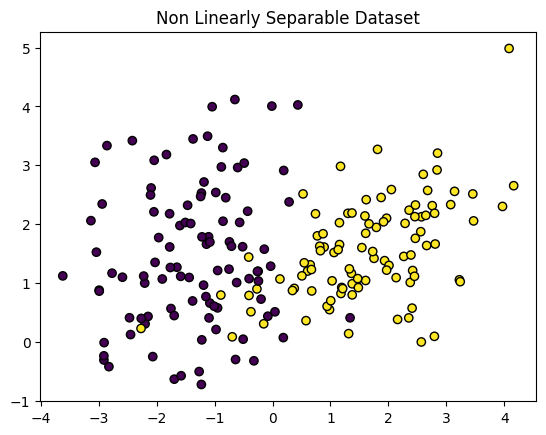

In [ ]:
X, y = make_classification(
    n_samples=200,
    n_features=2,
    n_redundant=0,
    n_clusters_per_class=1,
    class_sep=1.5,
    random_state=42
)

plt.scatter(X[:,0], X[:,1], c=y, edgecolors='k')
plt.title("Non Linearly Separable Dataset")
plt.show()

#Strictly Linearly Seperable

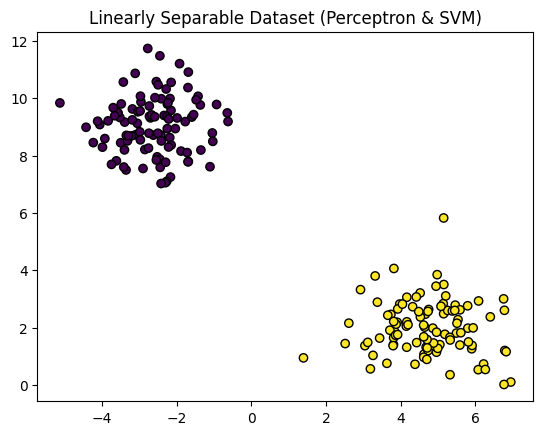

In [ ]:
X_lin, y_lin = make_blobs(
    n_samples=200,
    centers=2,
    n_features=2,
    cluster_std=1.0,
    random_state=42
)

plt.scatter(X_lin[:,0], X_lin[:,1], c=y_lin, edgecolors='k')
plt.title("Linearly Separable Dataset (Perceptron & SVM)")
plt.show()


# Logistic Regression

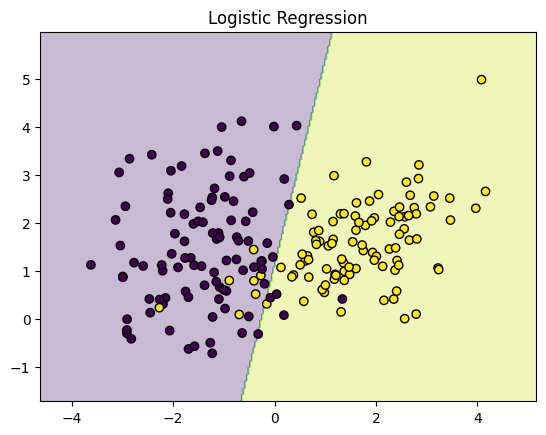

In [ ]:
logreg = LogisticRegression()
logreg.fit(X, y)

plot_decision_boundary(logreg, X, y, "Logistic Regression")


#Perceptron — FROM SCRATCH

In [ ]:
class PerceptronScratch:
    def __init__(self, lr=0.1):
        self.lr = lr

    def fit(self, X, y, epochs=1):
        if not hasattr(self, "w"):
            self.w = np.zeros(X.shape[1])
            self.b = 0

        for _ in range(epochs):
            for xi, yi in zip(X, y):
                yi = 1 if yi == 1 else -1
                if yi * (np.dot(xi, self.w) + self.b) <= 0:
                    self.w += self.lr * yi * xi
                    self.b += self.lr * yi

    def predict(self, X):
        return (np.dot(X, self.w) + self.b >= 0).astype(int)


#Movement of Decision Boundary

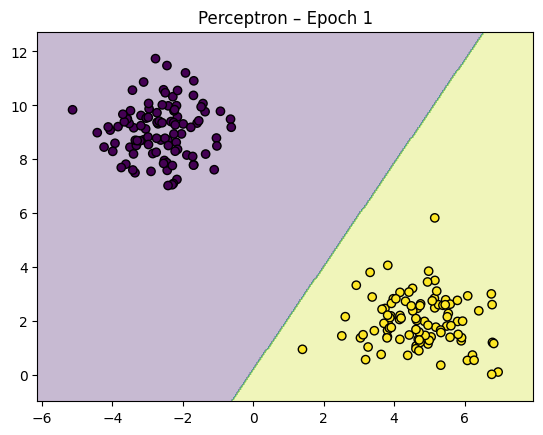

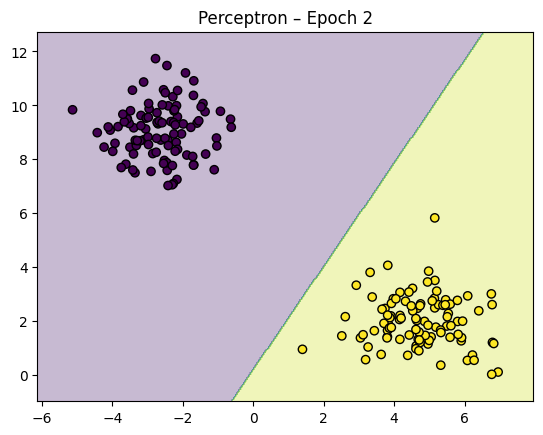

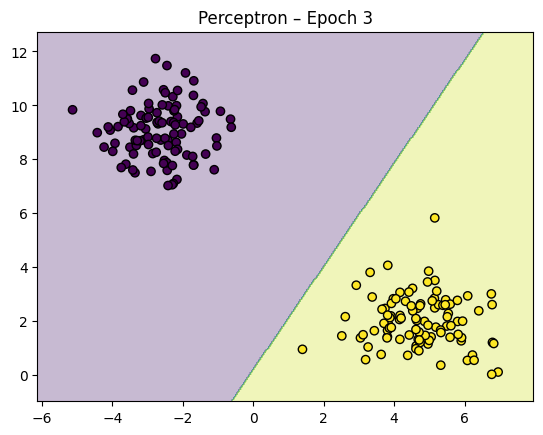

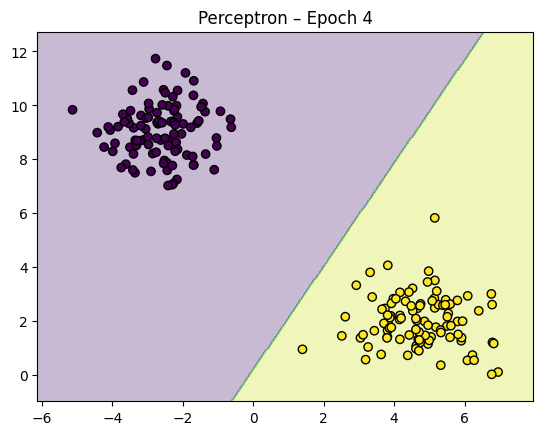

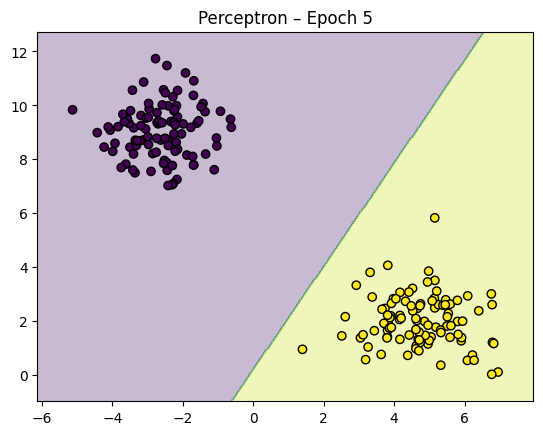

In [ ]:
perceptron = PerceptronScratch(lr=0.05)

for epoch in range(1, 6):
    perceptron.fit(X_lin, y_lin, epochs=1)
    plot_decision_boundary(
        perceptron,
        X_lin,
        y_lin,
        f"Perceptron – Epoch {epoch}"
    )


#SVM (sklearn) + Supporting Hyperplanes

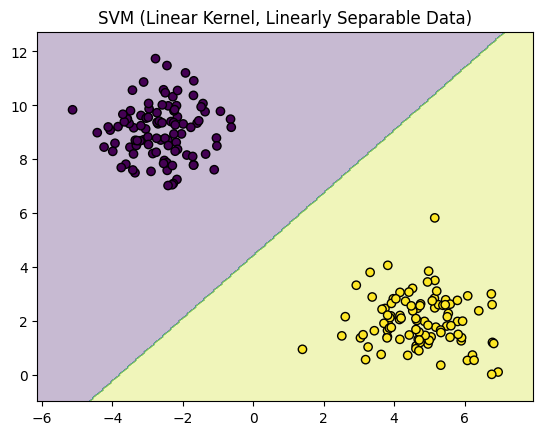

In [ ]:
svm = SVC(kernel="linear", C=1.0)
svm.fit(X_lin, y_lin)

plot_decision_boundary(
    svm,
    X_lin,
    y_lin,
    "SVM (Linear Kernel, Linearly Separable Data)"
)


#SVM SUPPORTING HYPERPLANES

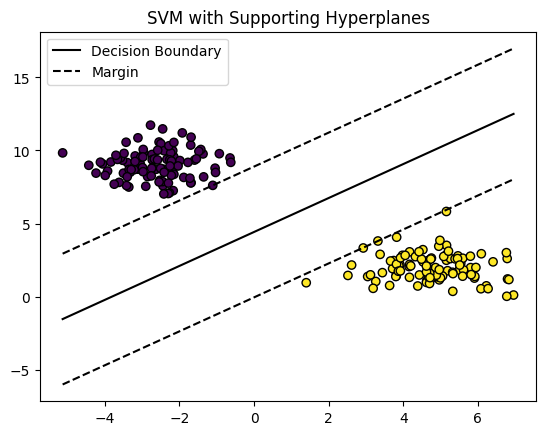

In [ ]:
w = svm.coef_[0]
b = svm.intercept_[0]

x_vals = np.linspace(X_lin[:, 0].min(), X_lin[:, 0].max(), 200)

plt.scatter(X_lin[:, 0], X_lin[:, 1], c=y_lin, edgecolors="k")
plt.plot(x_vals, -(w[0]*x_vals + b) / w[1], 'k', label="Decision Boundary")
plt.plot(x_vals, -(w[0]*x_vals + b - 1) / w[1], 'k--', label="Margin")
plt.plot(x_vals, -(w[0]*x_vals + b + 1) / w[1], 'k--')
plt.legend()
plt.title("SVM with Supporting Hyperplanes")
plt.show()


#SVM Non Linear

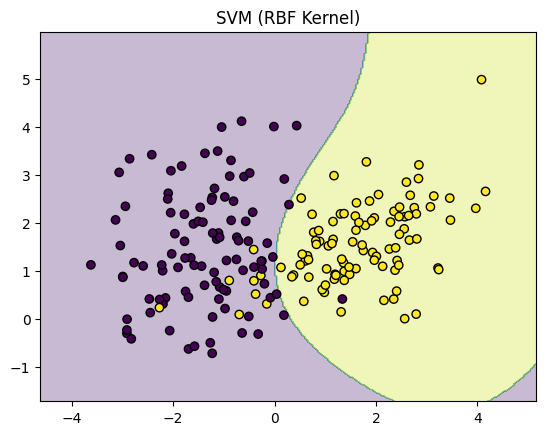

In [ ]:
# =========================================
# SVM (sklearn)
# =========================================

from sklearn.svm import SVC

svm_model = SVC(
    C=1.0,                 # Regularization parameter
                            # ↑ C → tries to classify all training points correctly
                            #        → LOW bias, HIGH variance (overfitting risk)
                            # ↓ C → allows more margin violations
                            #        → HIGH bias, LOW variance

    kernel="rbf",          # Kernel type
                            # 'linear' → straight boundary
                            # 'rbf' → non-linear curved boundary

    gamma="scale"          # Controls influence of single training example
                            # ↑ gamma → tight boundary around points (overfitting)
                            # ↓ gamma → smoother boundary (underfitting possible)
)

svm_model.fit(X, y)
plot_decision_boundary(svm_model, X, y, "SVM (RBF Kernel)")

#k-NN (sklearn)

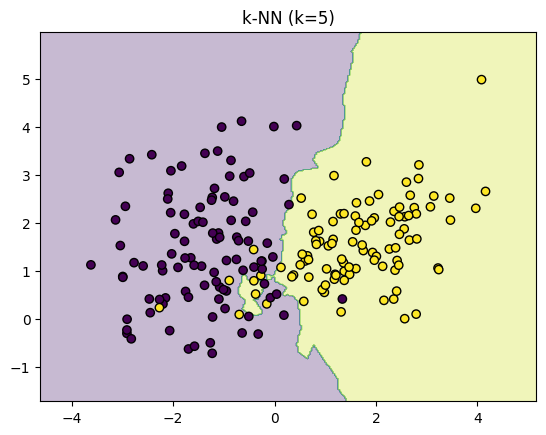

In [ ]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X, y)

plot_decision_boundary(knn, X, y, "k-NN (k=5)")


#Decision Tree (sklearn)

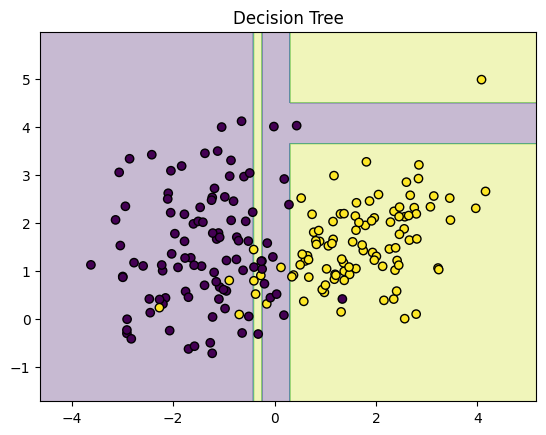

In [ ]:
tree = DecisionTreeClassifier(max_depth=3)
tree.fit(X, y)

plot_decision_boundary(tree, X, y, "Decision Tree")


#Tree Diagram

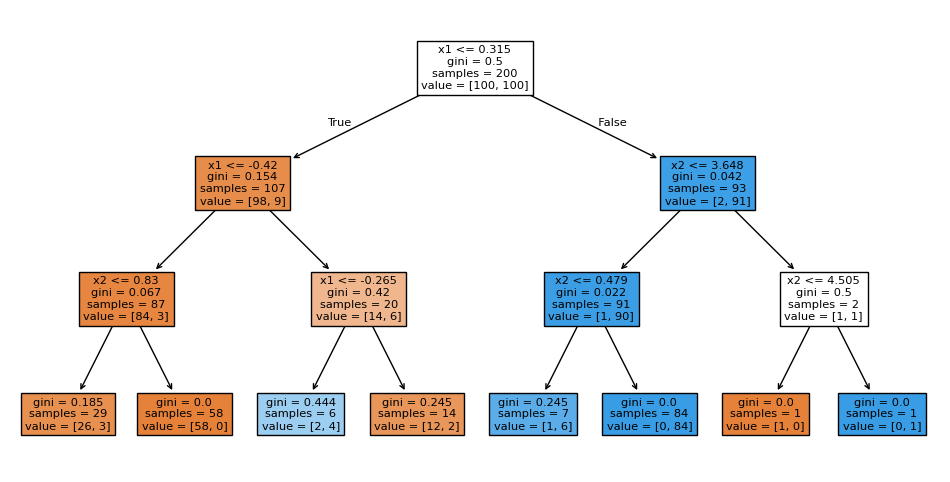

In [ ]:
plt.figure(figsize=(12, 6))
plot_tree(tree, filled=True, feature_names=["x1", "x2"])
plt.show()


#Decision Tree - HyperParameters

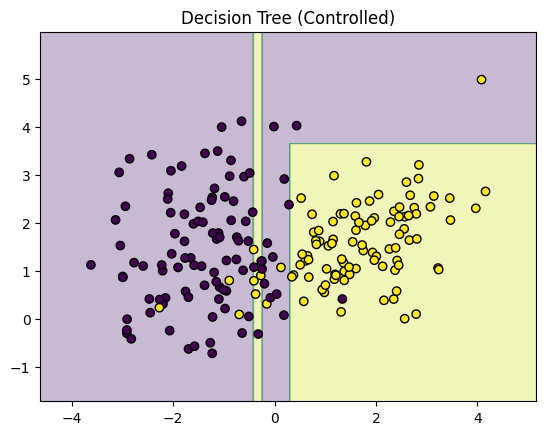

In [ ]:
# =========================================
# Decision Tree (sklearn)
# =========================================


tree = DecisionTreeClassifier(

    criterion="gini",        # Metric used to measure quality of a split
                              # "gini"  → Gini Impurity (default)
                              # "entropy" → Information Gain

                              # Both measure how "pure" a node is.
                              # Lower impurity → better split.

                              # In practice:
                              # - gini is slightly faster computationally
                              # - entropy can be slightly more precise
                              # Difference is usually small in real problems

    max_depth=3,             # Maximum depth of the tree
                              # ↓ smaller value → simpler tree → HIGH bias, LOW variance
                              # ↑ larger value → complex tree → LOW bias, HIGH variance
                              # Very large depth → overfitting

    min_samples_split=5,     # Minimum samples required to split a node
                              # ↑ larger value → fewer splits → more regularization
                              # ↓ smaller value → more splits → can overfit

    min_samples_leaf=2,      # Minimum samples required at a leaf node
                              # ↑ larger value → smoother boundaries → reduces overfitting
                              # ↓ smaller value → more flexible → higher variance

    random_state=42
)

tree.fit(X, y)
plot_decision_boundary(tree, X, y, "Decision Tree (Controlled)")

#Random Forest (sklearn)

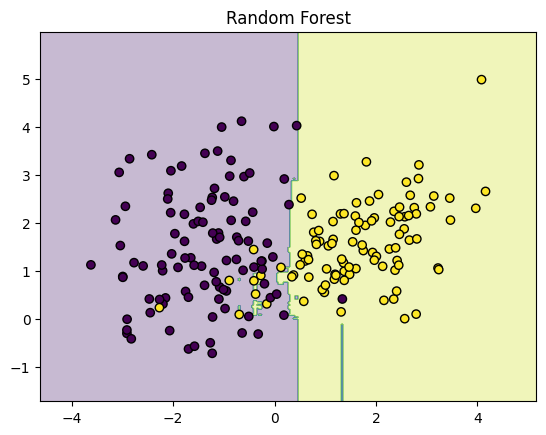

In [ ]:
rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    random_state=42
)
rf.fit(X, y)

plot_decision_boundary(rf, X, y, "Random Forest")


#Random Forest Tuning

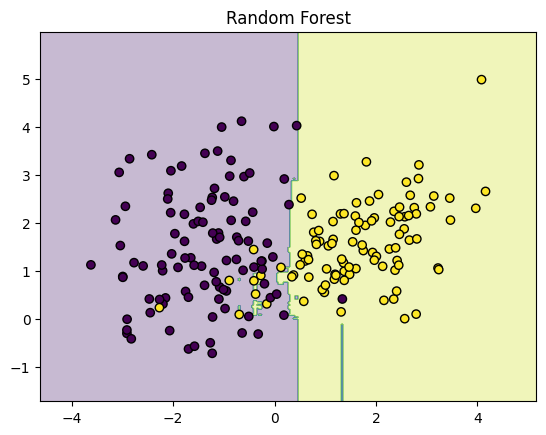

In [ ]:
# =========================================
# Random Forest (sklearn)
# =========================================

from sklearn.ensemble import RandomForestClassifier


rf = RandomForestClassifier(

    n_estimators=100,       # Number of trees in the forest
                            # ↑ more trees → lower variance → better generalization
                            # ↓ fewer trees → faster but less stable predictions
                            # After a point, improvement plateaus

    criterion="gini",       # Function to measure quality of a split
                            # "gini"    → Gini Impurity (default, slightly faster)
                            # "entropy" → Information Gain

                            # Just like Decision Tree:
                            # Both measure node impurity.
                            # Difference is usually small in practice.

    max_depth=5,            # Maximum depth of each tree
                            # ↓ small depth → higher bias, lower variance (underfitting risk)
                            # ↑ large depth → lower bias, higher variance
                            # BUT Random Forest reduces overfitting
                            # because averaging many trees lowers variance

    max_features="sqrt",    # Number of features considered at each split
                            # "sqrt" → common default for classification
                            # Smaller value → more randomness → lower correlation between trees
                            # Lower correlation → better variance reduction

    random_state=42
)

rf.fit(X, y)
plot_decision_boundary(rf, X, y, "Random Forest")

#Gradient Boosted Decision Trees (sklearn)

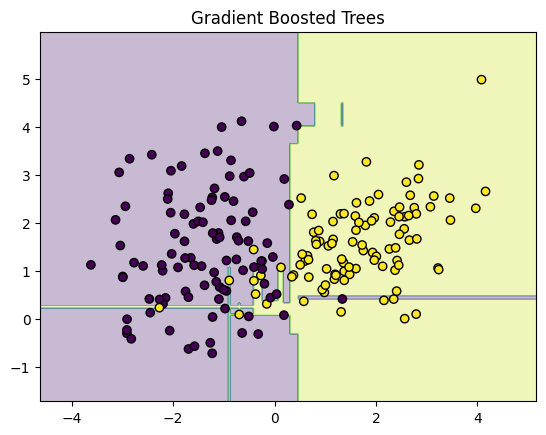

In [ ]:
gbdt = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3
)
gbdt.fit(X, y)

plot_decision_boundary(gbdt, X, y, "Gradient Boosted Trees")


#XGBoost (sklearn)

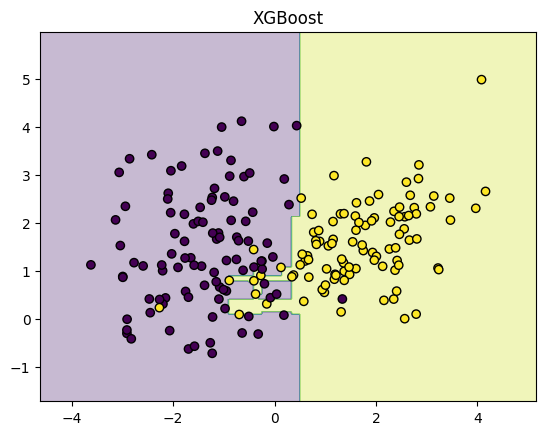

In [ ]:
import xgboost as xgb

xgb_clf = xgb.XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3
)
xgb_clf.fit(X, y)

plot_decision_boundary(xgb_clf, X, y, "XGBoost")